In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AI_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(AI_ROOT))

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (7, 3.5)

In [2]:
USE_FAKE = True  # True = skip Postgres and use data/fake/*.csv

def load_all():
    if not USE_FAKE:
        try:
            from api.dependencies import load_users, load_content, load_engagements
            return load_users(), load_content(), load_engagements(), "postgres"
        except Exception as e:
            print(f"DB not available ({type(e).__name__}), using fake CSVs")
    d = AI_ROOT / "data" / "fake"
    return (pd.read_csv(d / "users.csv"), pd.read_csv(d / "content.csv"),
            pd.read_csv(d / "engagements.csv"), "fake csv")

users, content, eng, SOURCE = load_all()

def parse(x):
    # CSV stores lists/dicts as JSON strings; Postgres already gives lists/dicts
    if isinstance(x, str):
        try:
            return json.loads(x)
        except json.JSONDecodeError:
            return x
    return x

users["preferences"] = users["preferences"].map(parse)
content["metadata"] = content["metadata"].map(parse)

for col in ("like", "save", "follow"):
    eng[col] = eng[col].fillna(False).astype(bool)
eng["has_comment"] = eng["comment"].fillna("").astype(str).str.strip().ne("")

print(f"source: {SOURCE}")
print(f"users={len(users)}  content={len(content)}  engagements={len(eng)}")

source: fake csv
users=300  content=1200  engagements=3938


In [3]:
for name, df in [("users", users), ("content", content), ("engagements", eng)]:
    print(f"--- {name} {df.shape}")
    print(df.isna().sum().to_string())

orphan_users = (~eng["userid"].isin(users["id"])).sum()
orphan_content = (~eng["contentid"].isin(content["id"])).sum()
dupes = eng.duplicated(["userid", "contentid"]).sum()
print(f"\nengagements with unknown user: {orphan_users}")
print(f"engagements with unknown content: {orphan_content}")
print(f"duplicate (user, content) pairs: {dupes}")

--- users (300, 4)
id             0
name           0
email          0
preferences    0
--- content (1200, 5)
id               0
creatoruserid    0
title            0
type             0
metadata         0
--- engagements (3938, 8)
id                0
userid            0
contentid         0
like              0
save              0
comment        3525
follow            0
has_comment       0

engagements with unknown user: 0
engagements with unknown content: 0
duplicate (user, content) pairs: 0


like           84.3
save           26.2
has_comment    10.5
follow          6.3


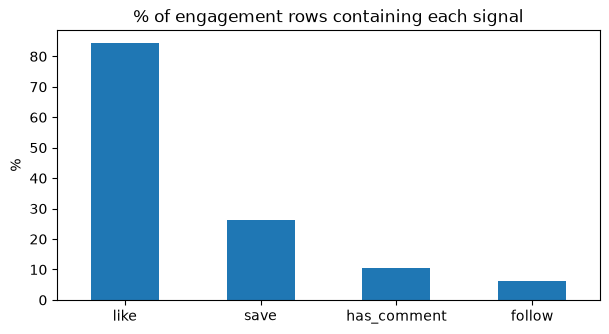

In [4]:
signals = eng[["like", "save", "has_comment", "follow"]].mean().mul(100).round(1)
print(signals.to_string())
signals.plot.bar(title="% of engagement rows containing each signal", rot=0)
plt.ylabel("%"); plt.show()

In [5]:
pairs = eng.drop_duplicates(["userid", "contentid"])
density = len(pairs) / (len(users) * len(content))
print(f"matrix {len(users)} x {len(content)}, density = {density:.2%}")

matrix 300 x 1200, density = 1.09%


content with zero engagements: 16%
top 10% of content gets 47% of engagements


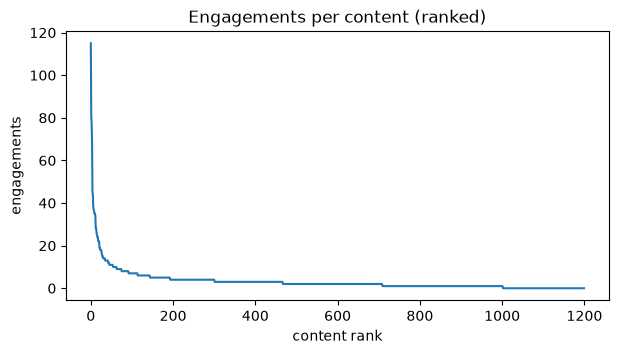

In [6]:
pop = (eng.groupby("contentid").size()
          .reindex(content["id"], fill_value=0)
          .sort_values(ascending=False))
top_share = pop.head(max(1, len(pop) // 10)).sum() / max(pop.sum(), 1)
print(f"content with zero engagements: {(pop == 0).mean():.0%}")
print(f"top 10% of content gets {top_share:.0%} of engagements")
pop.reset_index(drop=True).plot(title="Engagements per content (ranked)")
plt.xlabel("content rank"); plt.ylabel("engagements"); plt.show()

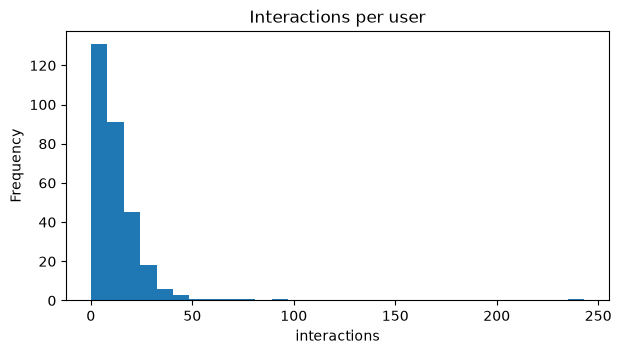

users with <  1 interactions: 9%
users with <  3 interactions: 20%
users with <  5 interactions: 25%
users with < 10 interactions: 47%


In [7]:
per_user = eng.groupby("userid").size().reindex(users["id"], fill_value=0)
per_user.plot.hist(bins=30, title="Interactions per user")
plt.xlabel("interactions"); plt.show()

for t in (1, 3, 5, 10):
    print(f"users with < {t:>2} interactions: {(per_user < t).mean():.0%}")

In [8]:
e = eng.merge(content[["id", "type"]].rename(columns={"id": "contentid"}),
              on="contentid", how="left")
by_type = e.groupby("type").agg(
    interactions=("id", "size"),
    like=("like", "mean"),
    save=("save", "mean"),
    comment=("has_comment", "mean"),
)
by_type["items"] = content.groupby("type").size()
by_type["per_item"] = by_type["interactions"] / by_type["items"]
display(by_type.round(3))

,interactions,like,save,comment,items,per_item
type,,,,,,
art,1139,0.845,0.261,0.114,291,3.914
performance,947,0.830,0.254,0.110,293,3.232
photography,802,0.864,0.241,0.101,314,2.554
writing,1050,0.836,0.286,0.093,302,3.477


In [9]:
pref_map = users.set_index("id")["preferences"].map(
    lambda p: set(p) if isinstance(p, (list, tuple, np.ndarray)) else set())

e["preferred"] = [t in pref_map.get(u, set()) for u, t in zip(e["userid"], e["type"])]
type_share = content["type"].value_counts(normalize=True)
expected = np.mean([sum(type_share.get(t, 0) for t in pref_map.get(u, set()))
                    for u in e["userid"]])
actual = e["preferred"].mean()
print(f"interactions on preferred types: {actual:.0%}")
print(f"expected if preferences were ignored: {expected:.0%}")
print(f"lift: {actual / expected:.1f}x")

interactions on preferred types: 83%
expected if preferences were ignored: 39%
lift: 2.1x


count    3938.00
mean        1.96
std         1.34
min         1.00
25%         1.00
50%         1.00
75%         3.00
max         8.00


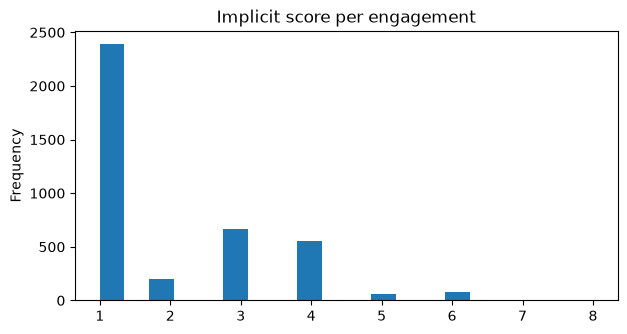

In [10]:
WEIGHTS = {"like": 1.0, "comment": 2.0, "save": 3.0, "follow": 2.0}  # starting point, tune in Part 4

eng["score"] = (eng["like"] * WEIGHTS["like"] + eng["has_comment"] * WEIGHTS["comment"]
                + eng["save"] * WEIGHTS["save"] + eng["follow"] * WEIGHTS["follow"])
print(eng["score"].describe().round(2).to_string())
eng["score"].plot.hist(bins=20, title="Implicit score per engagement")
plt.show()